# Home Credit — Exploratory Data Analysis

This notebook regenerates the EDA figures and audit tables from the supplied competition files. It is intended to be run from the project root. All plots are descriptive; associations with `TARGET` are not causal claims. No external data is used.

## 1. Dataset and target overview

Train contains 171,202 rows and 34 columns; test contains 61,500 rows and 33 columns. The target positive rate is approximately 8.07%, so class imbalance is substantial. The ID is retained for submission but excluded from model features.

In [1]:
from pathlib import Path
import runpy
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'src/eda.py').exists():
    ROOT = Path('..').resolve()
runpy.run_path(str(ROOT / 'src/eda.py'), run_name='__main__')

{
  "train_shape": [
    171202,
    34
  ],
  "test_shape": [
    61500,
    33
  ],
  "target_counts": {
    "0": 157381,
    "1": 13821
  },
  "positive_rate": 0.08072919708881905,
  "numeric_predictors": 24,
  "categorical_predictors": 8,
  "categorical_cardinality": {
    "NAME_CONTRACT_TYPE": 2,
    "CODE_GENDER": 3,
    "NAME_INCOME_TYPE": 8,
    "NAME_EDUCATION_TYPE": 5,
    "NAME_FAMILY_STATUS": 6,
    "NAME_HOUSING_TYPE": 6,
    "OCCUPATION_TYPE": 19,
    "ORGANIZATION_TYPE": 58
  },
  "id_unique_train": true,
  "id_unique_test": true,
  "id_overlap": 0,
  "test_ids_match_sample_order": true
}
Wrote EDA figures and tables to /mnt/data/work_hc/homecredit_ml_project/outputs/eda


{'__name__': '__main__',
 '__doc__': 'Generate reproducible exploratory-analysis tables and figures for Home Credit.',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/mnt/data/work_hc/homecredit_ml_project/src/eda.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '_

## 2. Target balance, missingness and numeric distributions

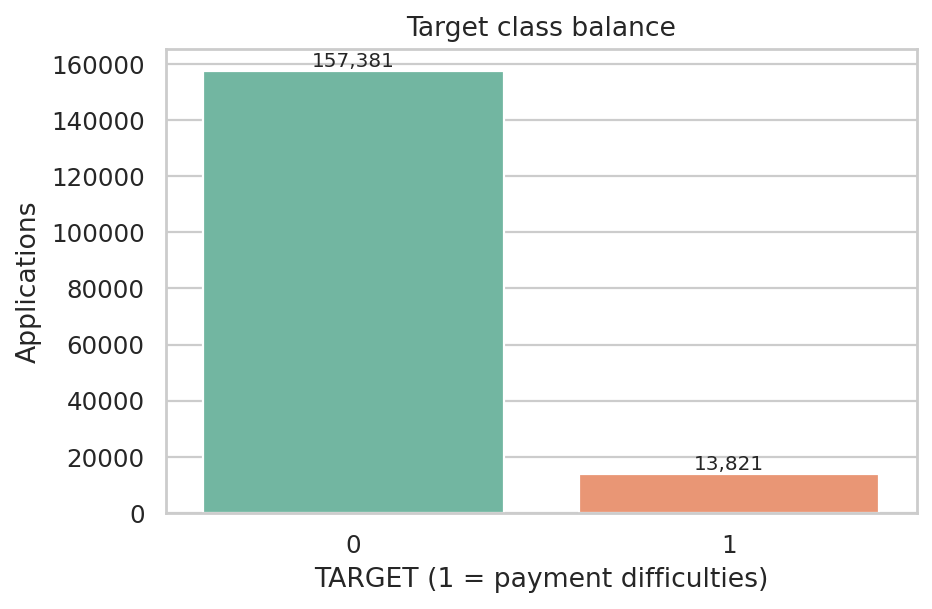

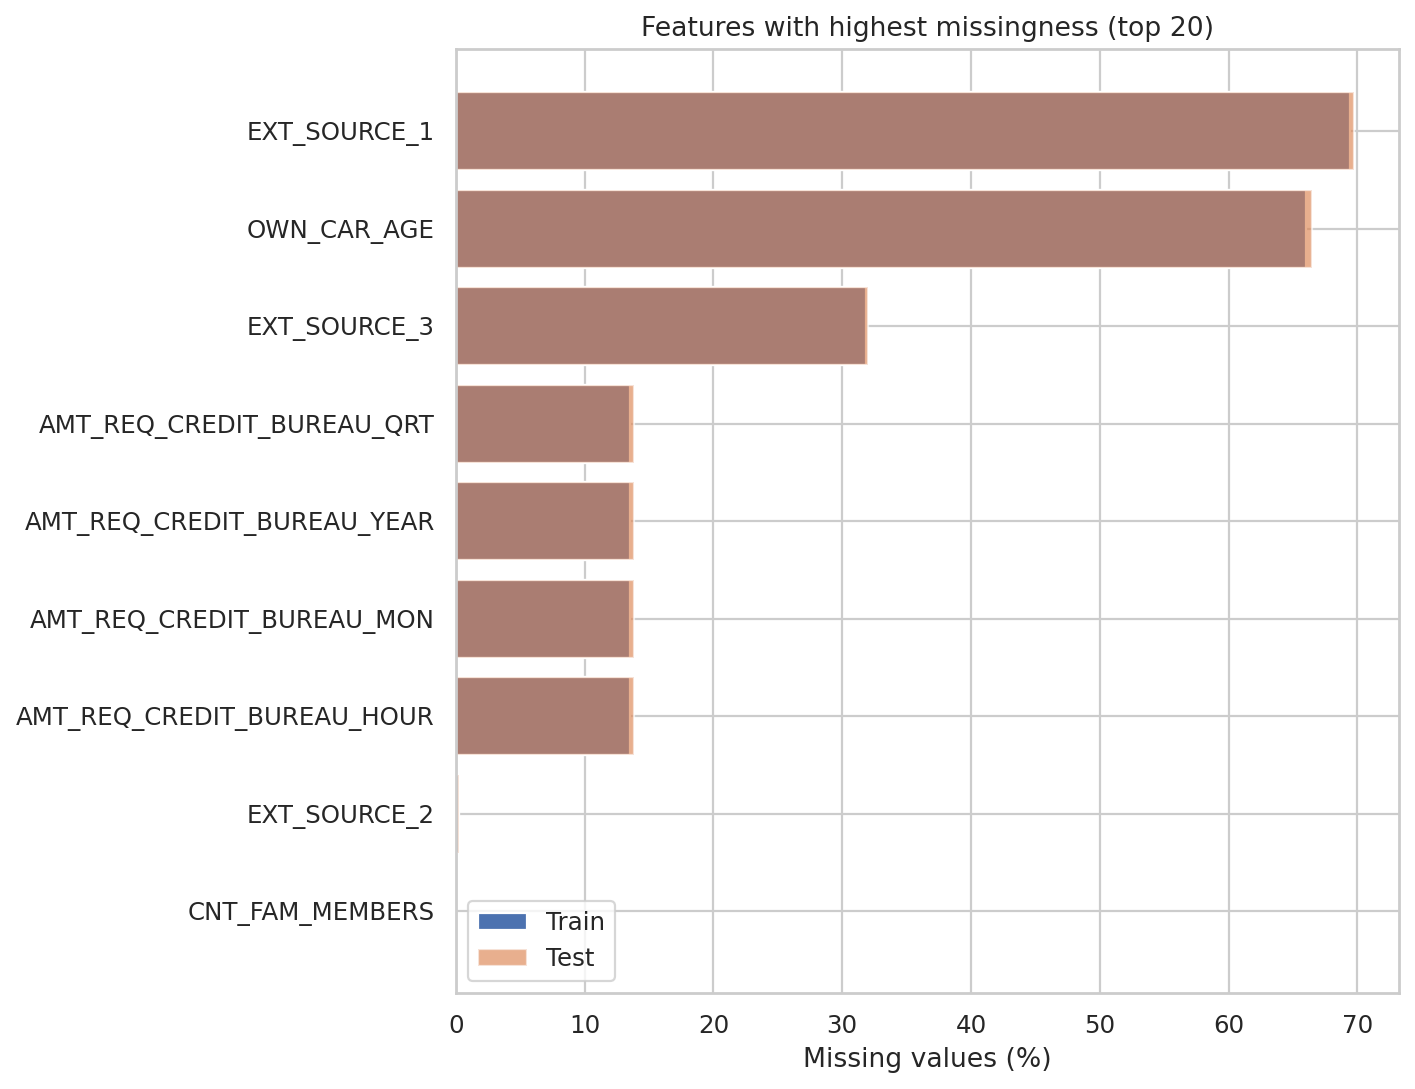

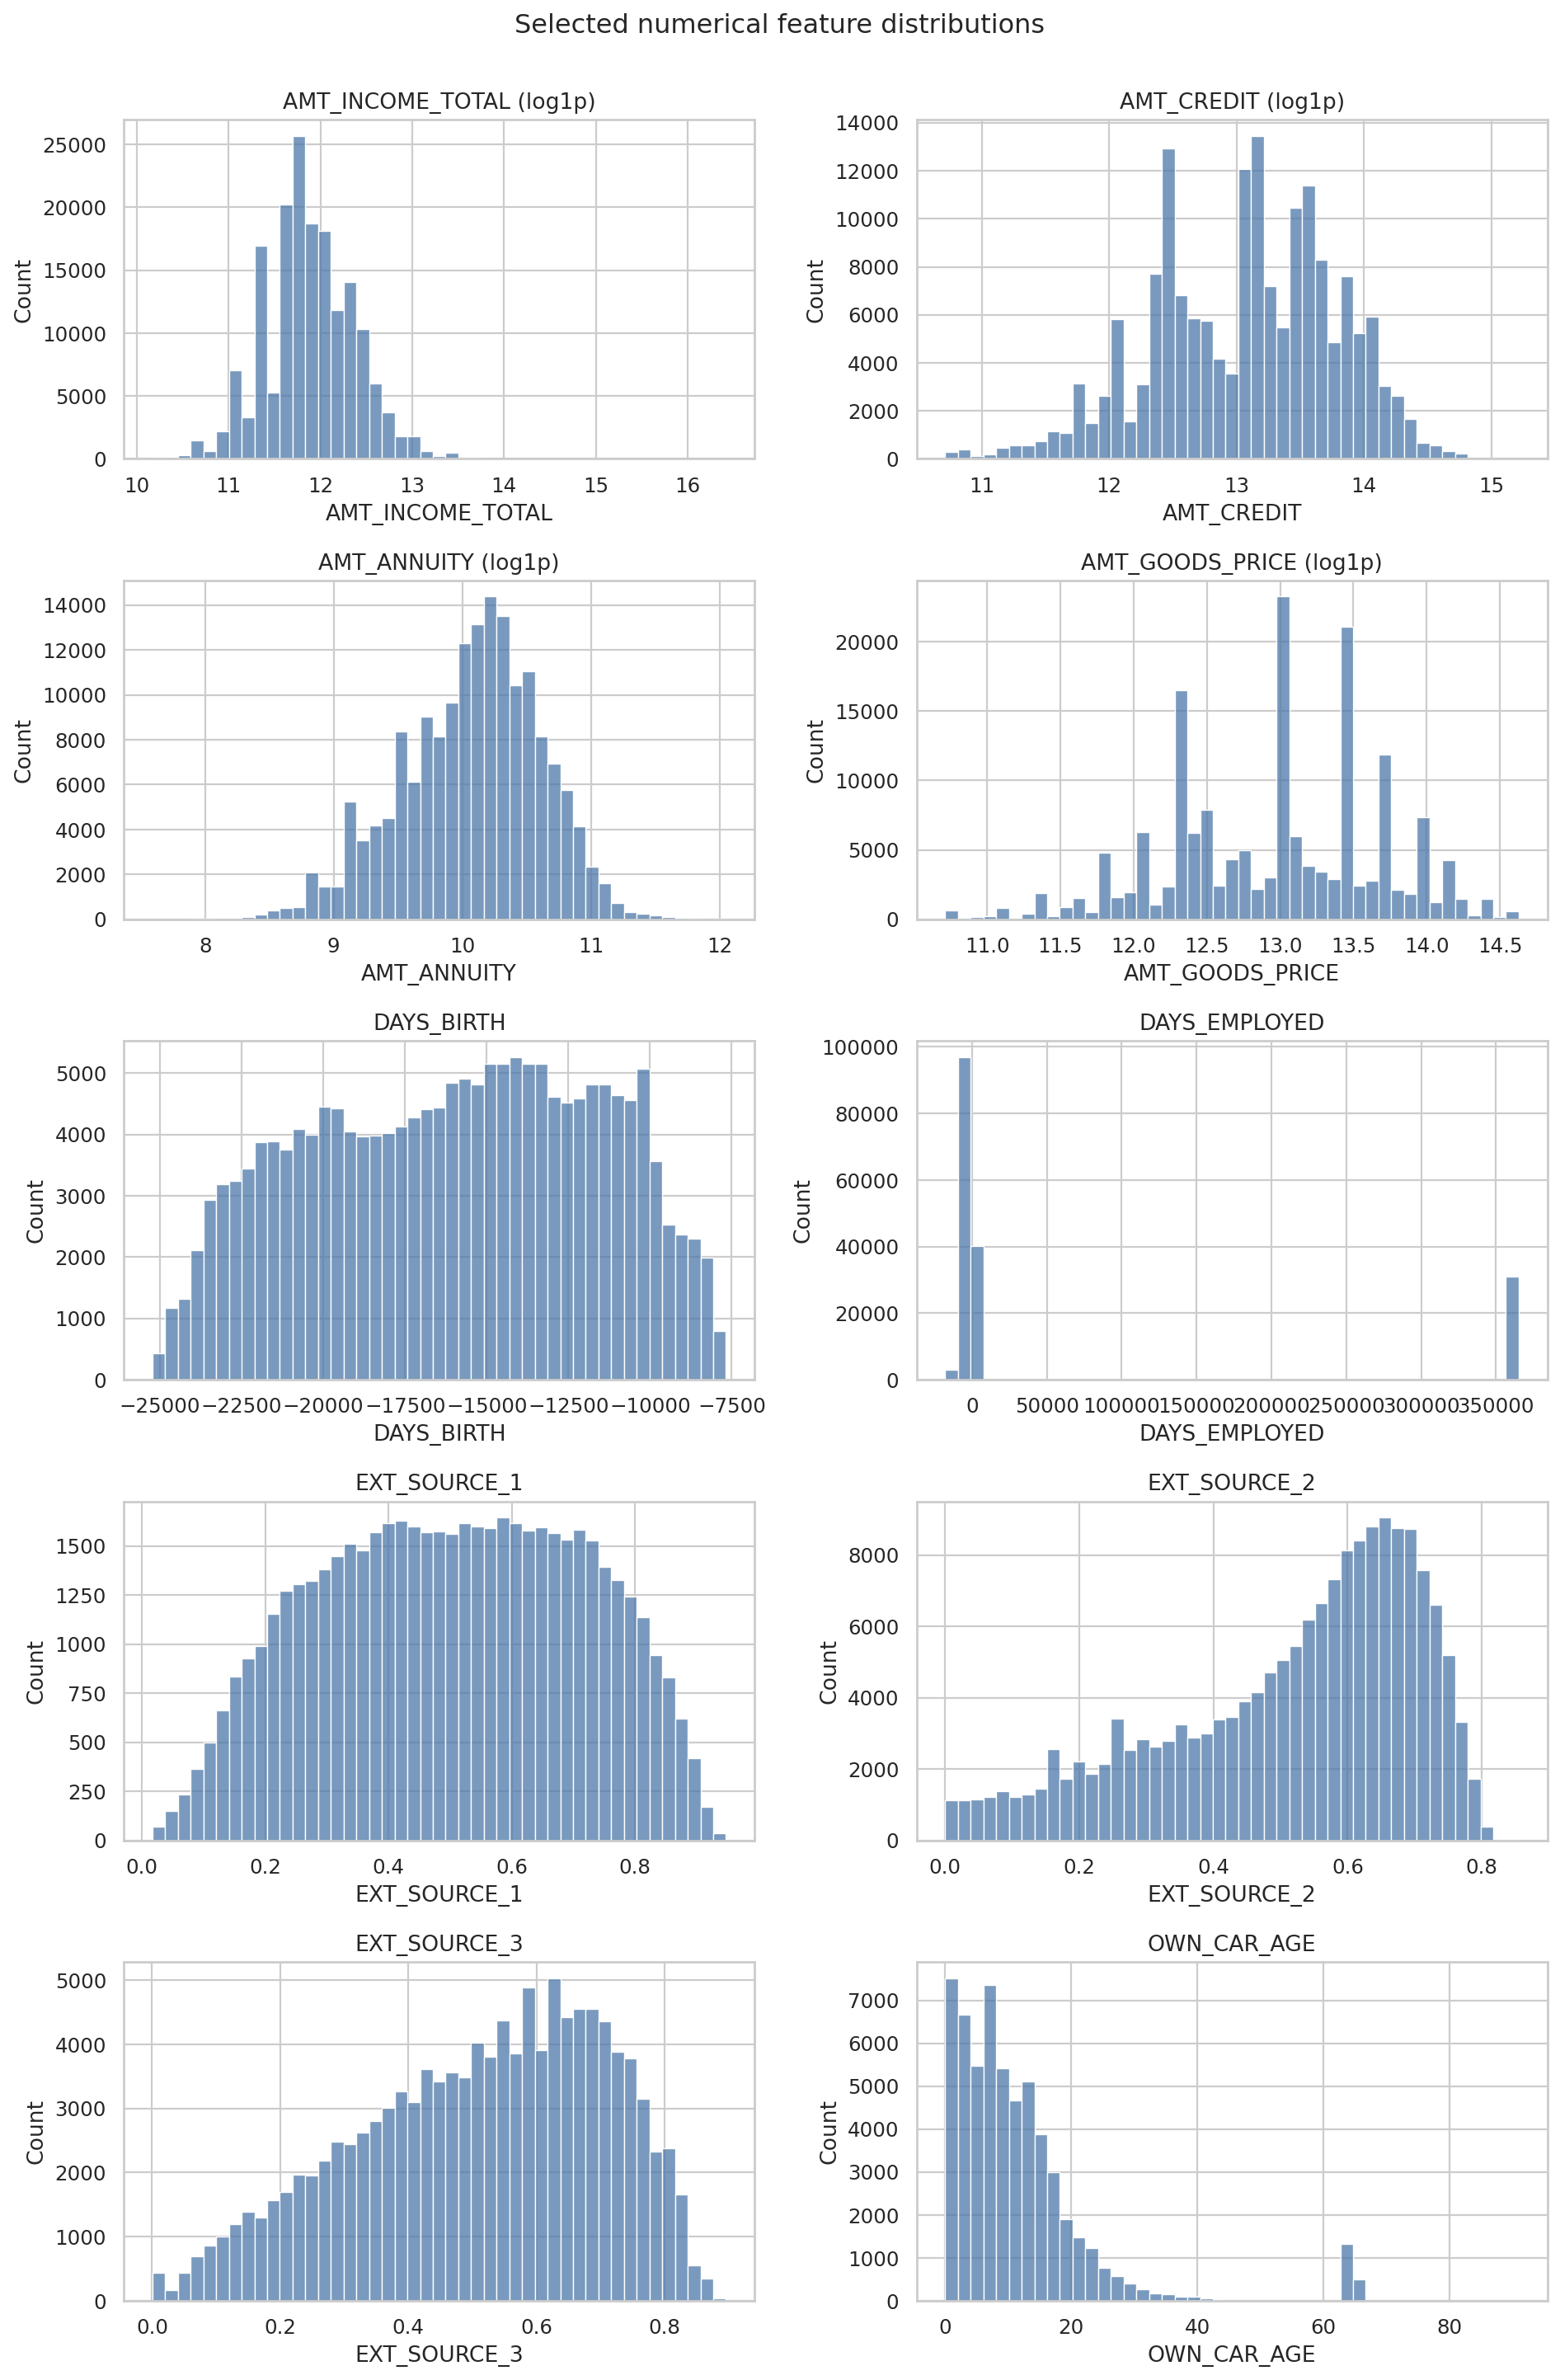

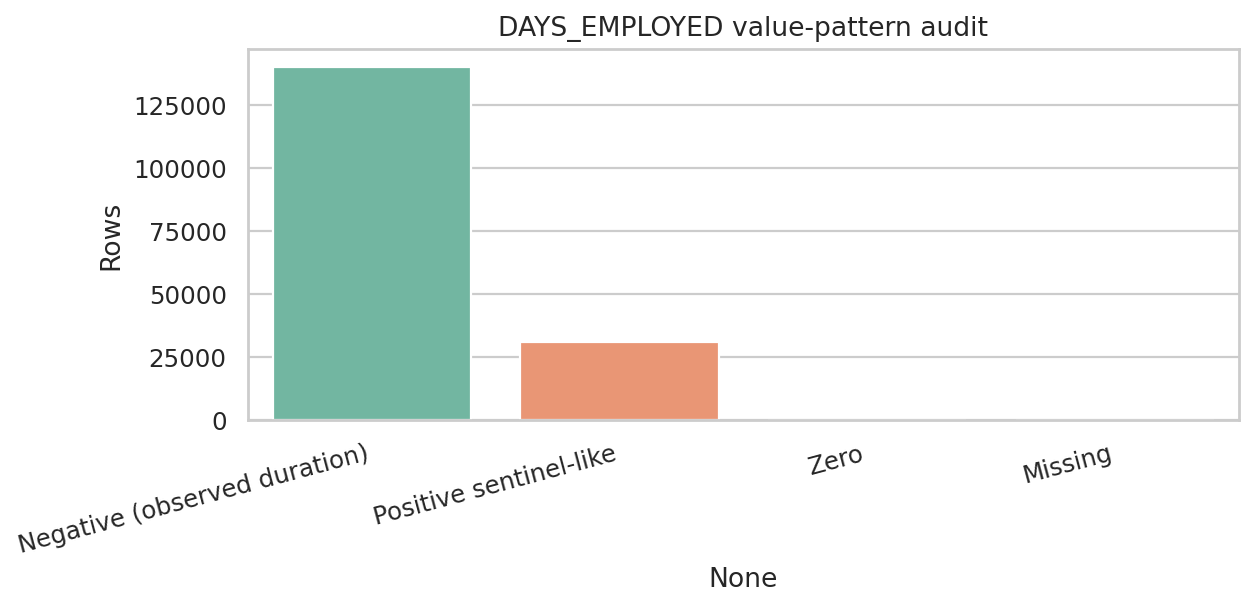

In [2]:
for f in ['01_target_balance.png','02_missingness.png','03_numeric_distributions.png','04_employment_sentinel.png']:
    display(Image(filename=str(ROOT / 'outputs/eda' / f)))

## 3. Relationships and categorical target rates

Target rates are shown only for categories with at least 30 observations. Small-category rates can be highly unstable. These are descriptive associations and should not be used as manual prediction rules.

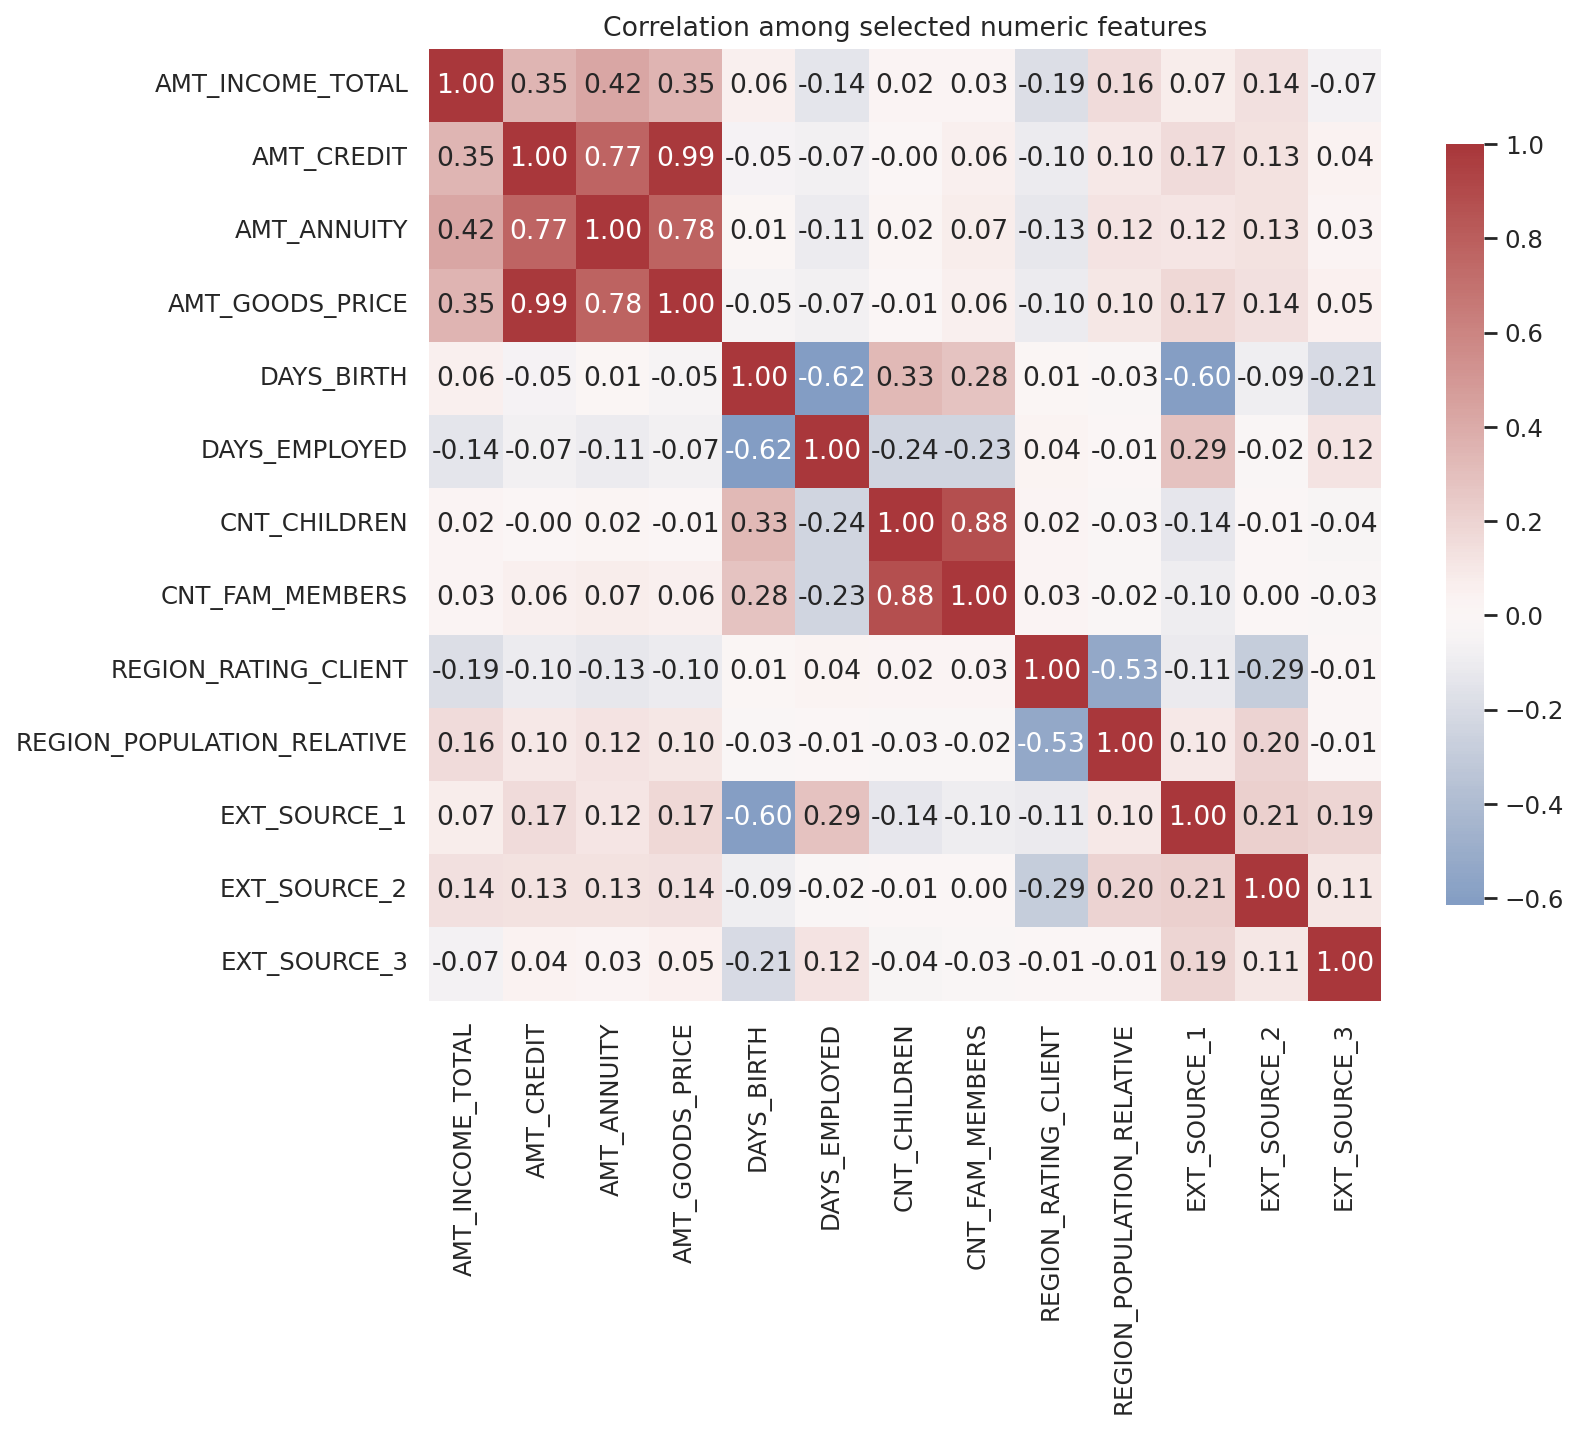

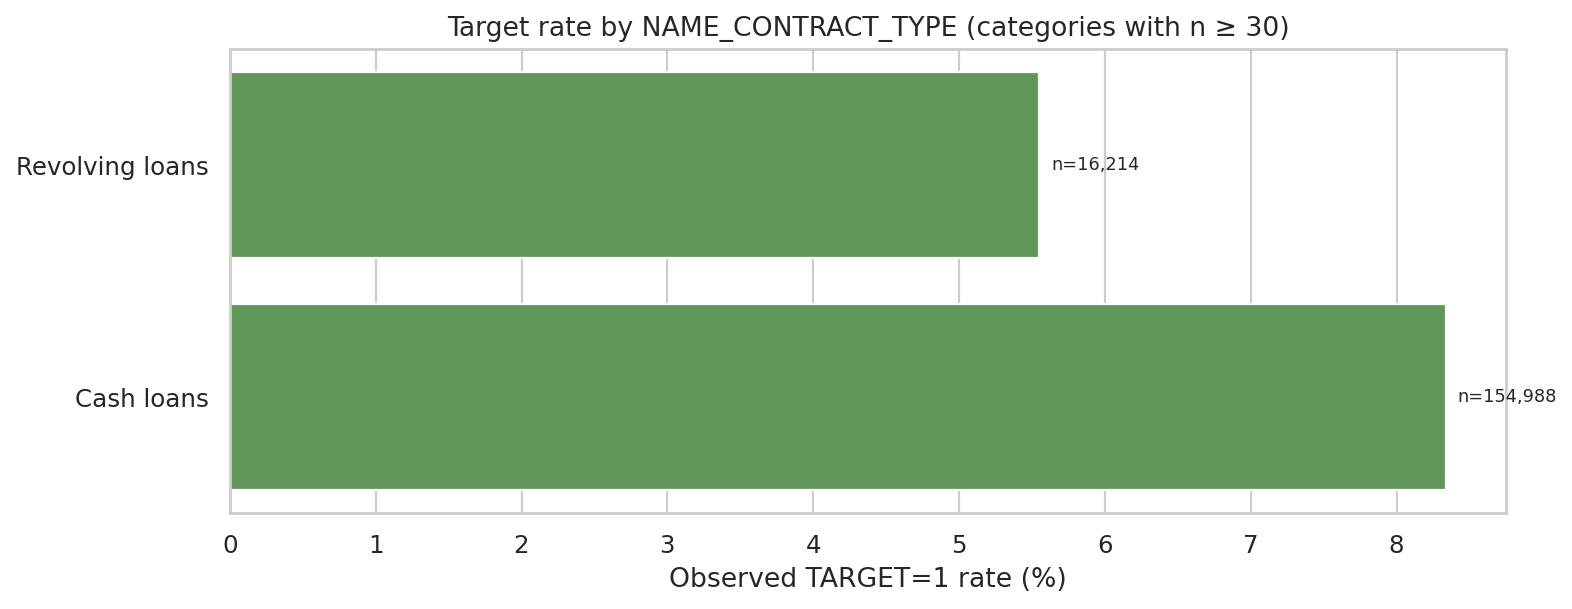

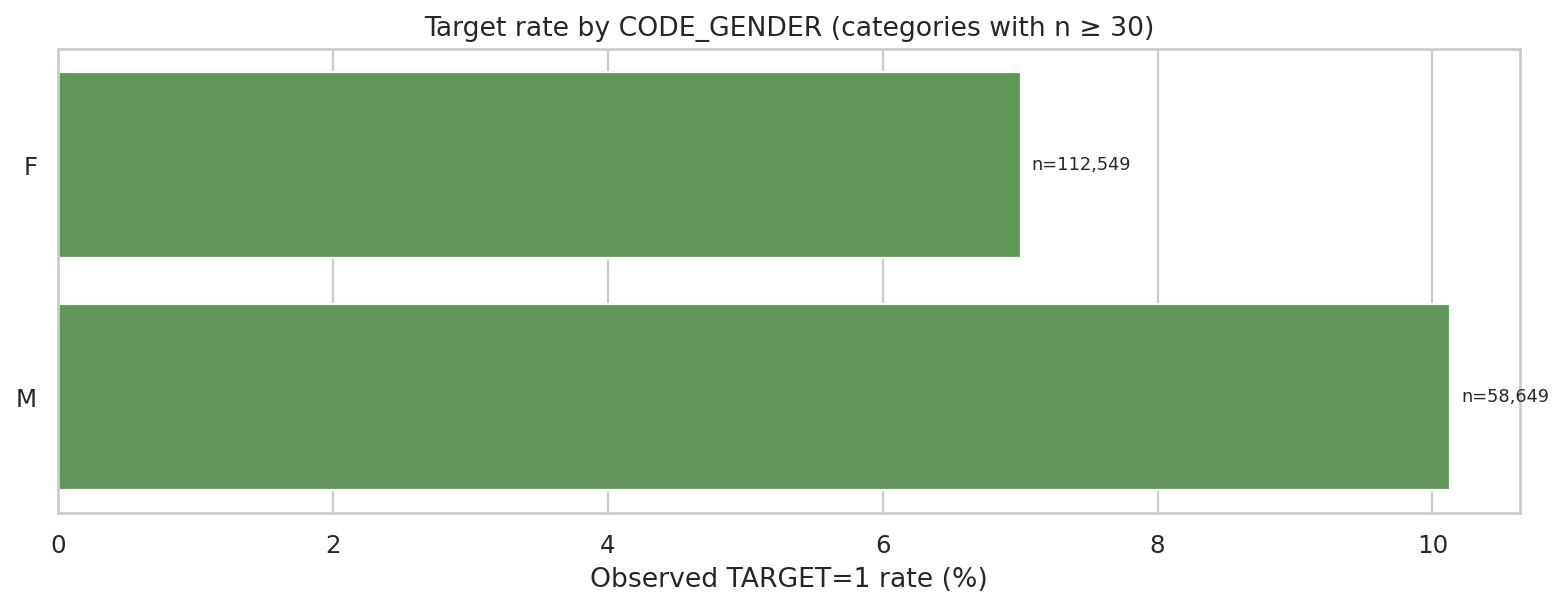

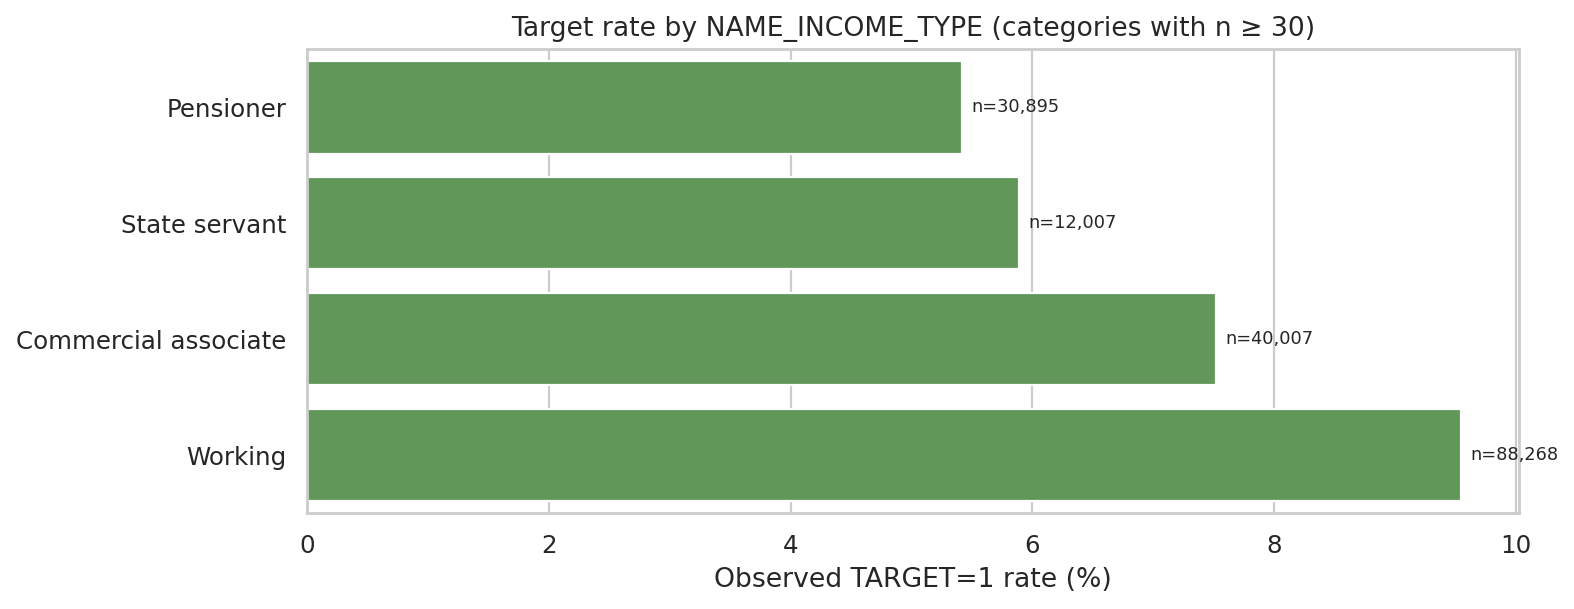

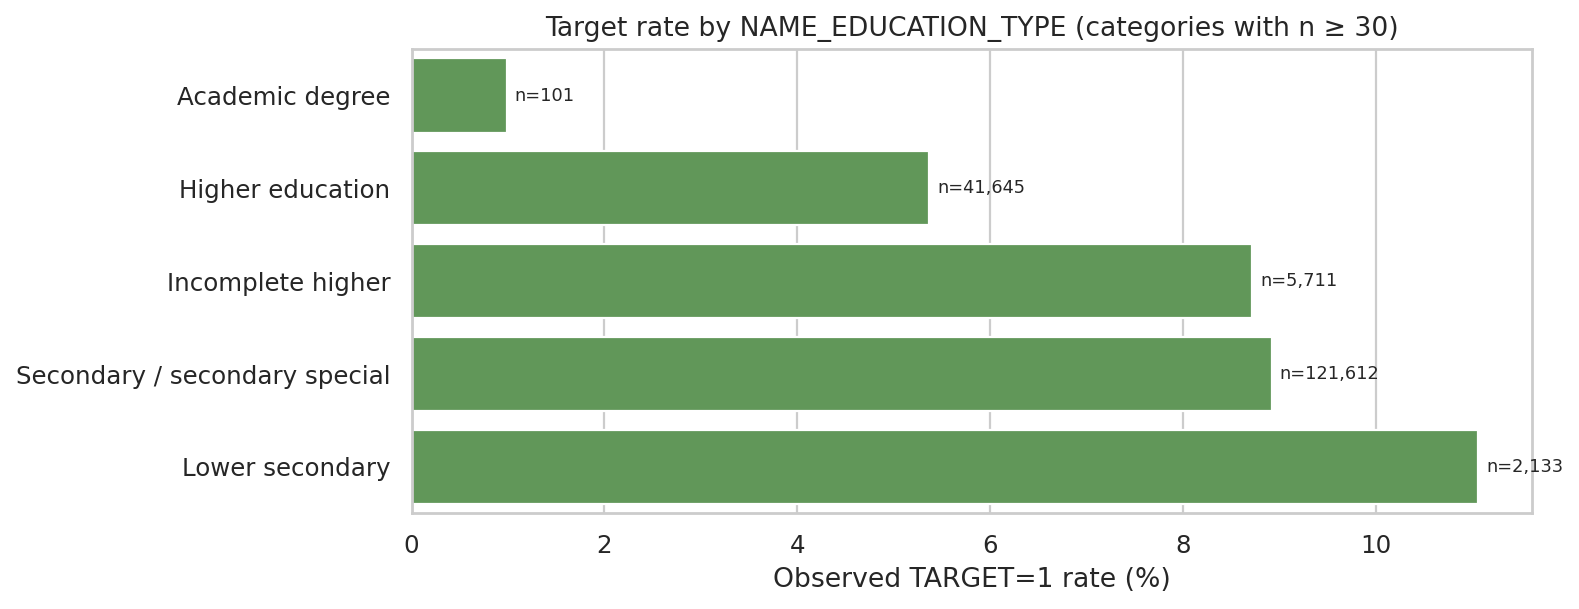

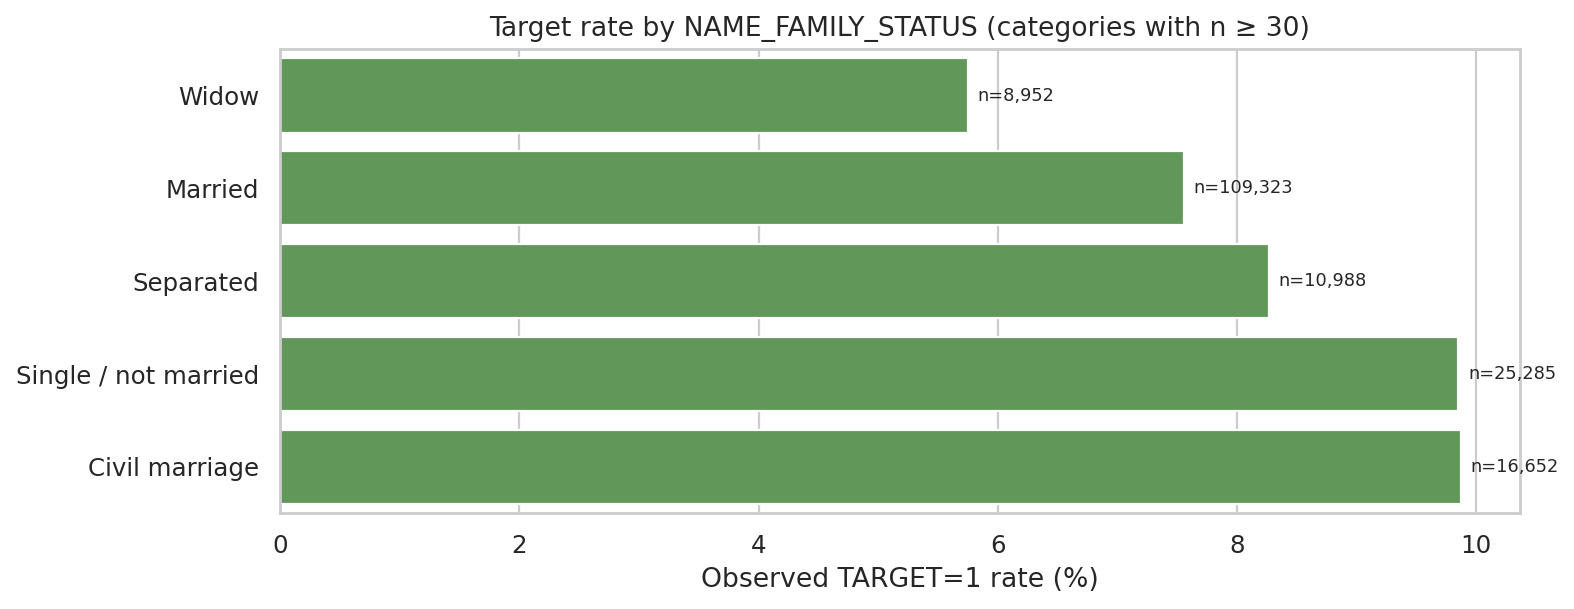

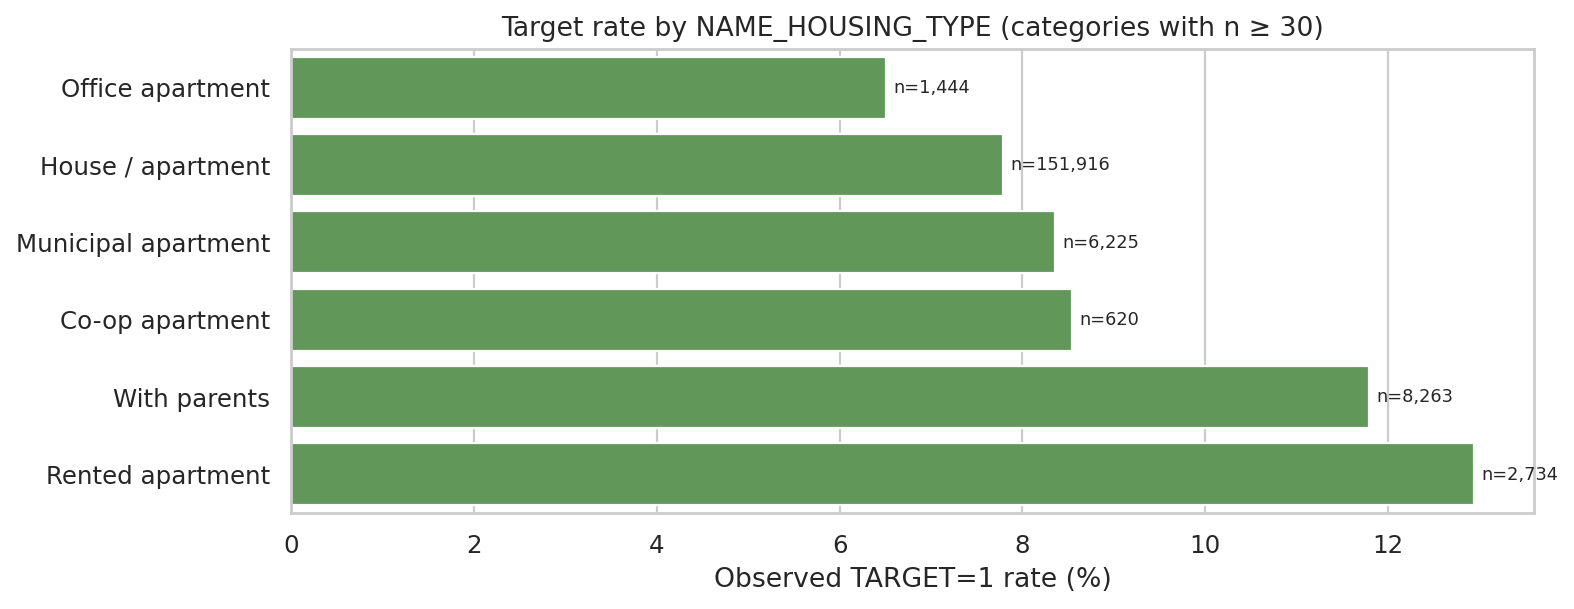

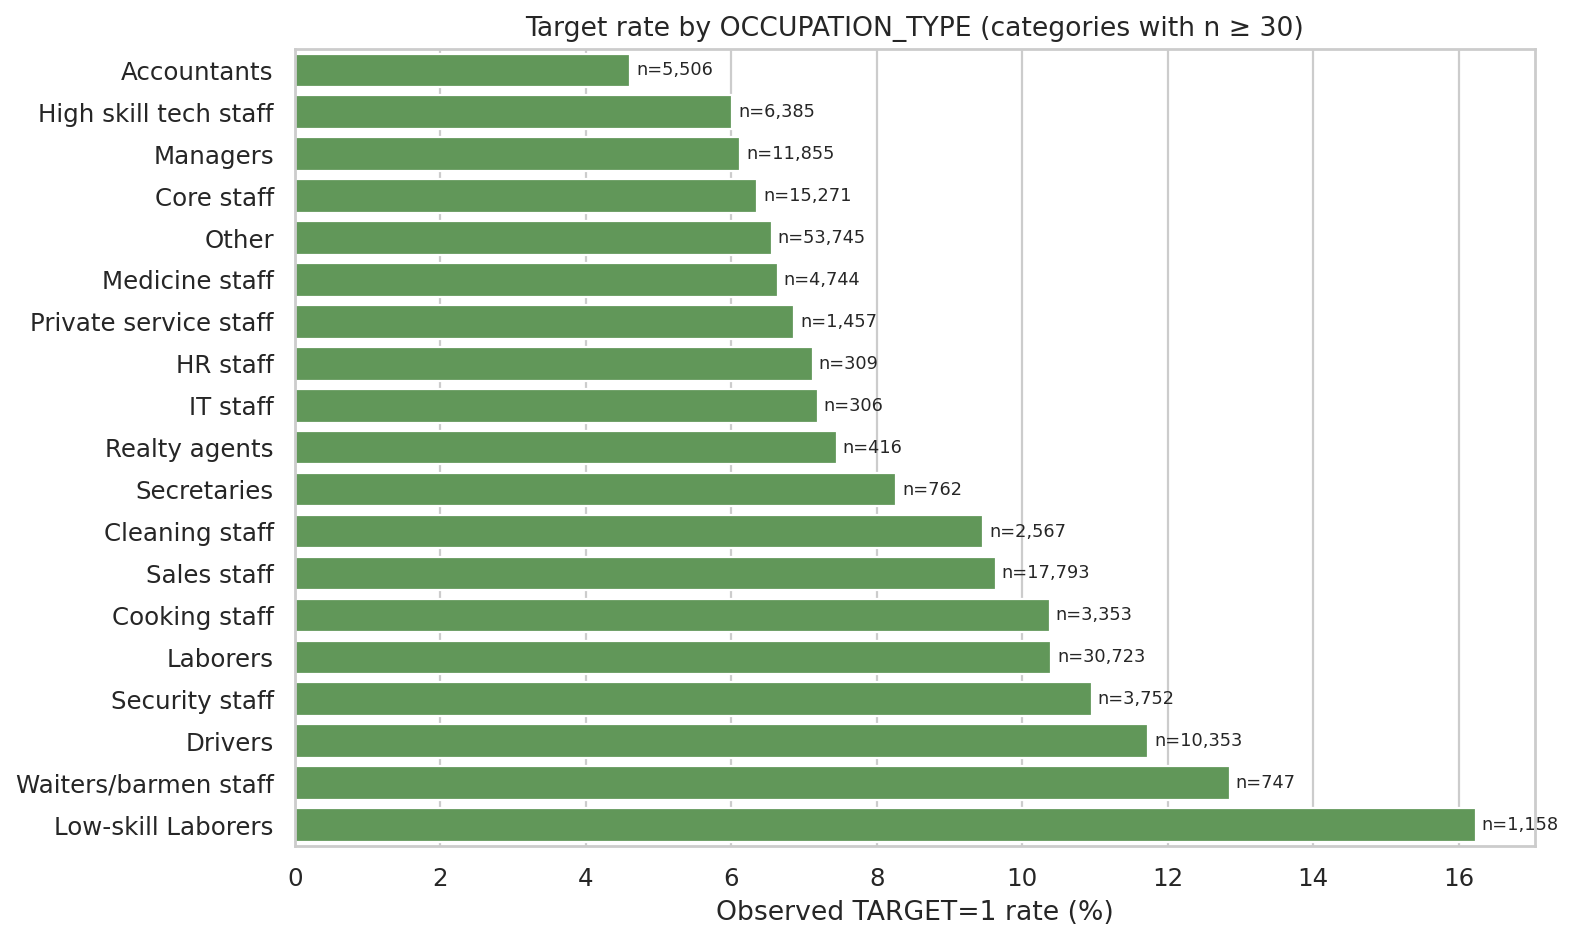

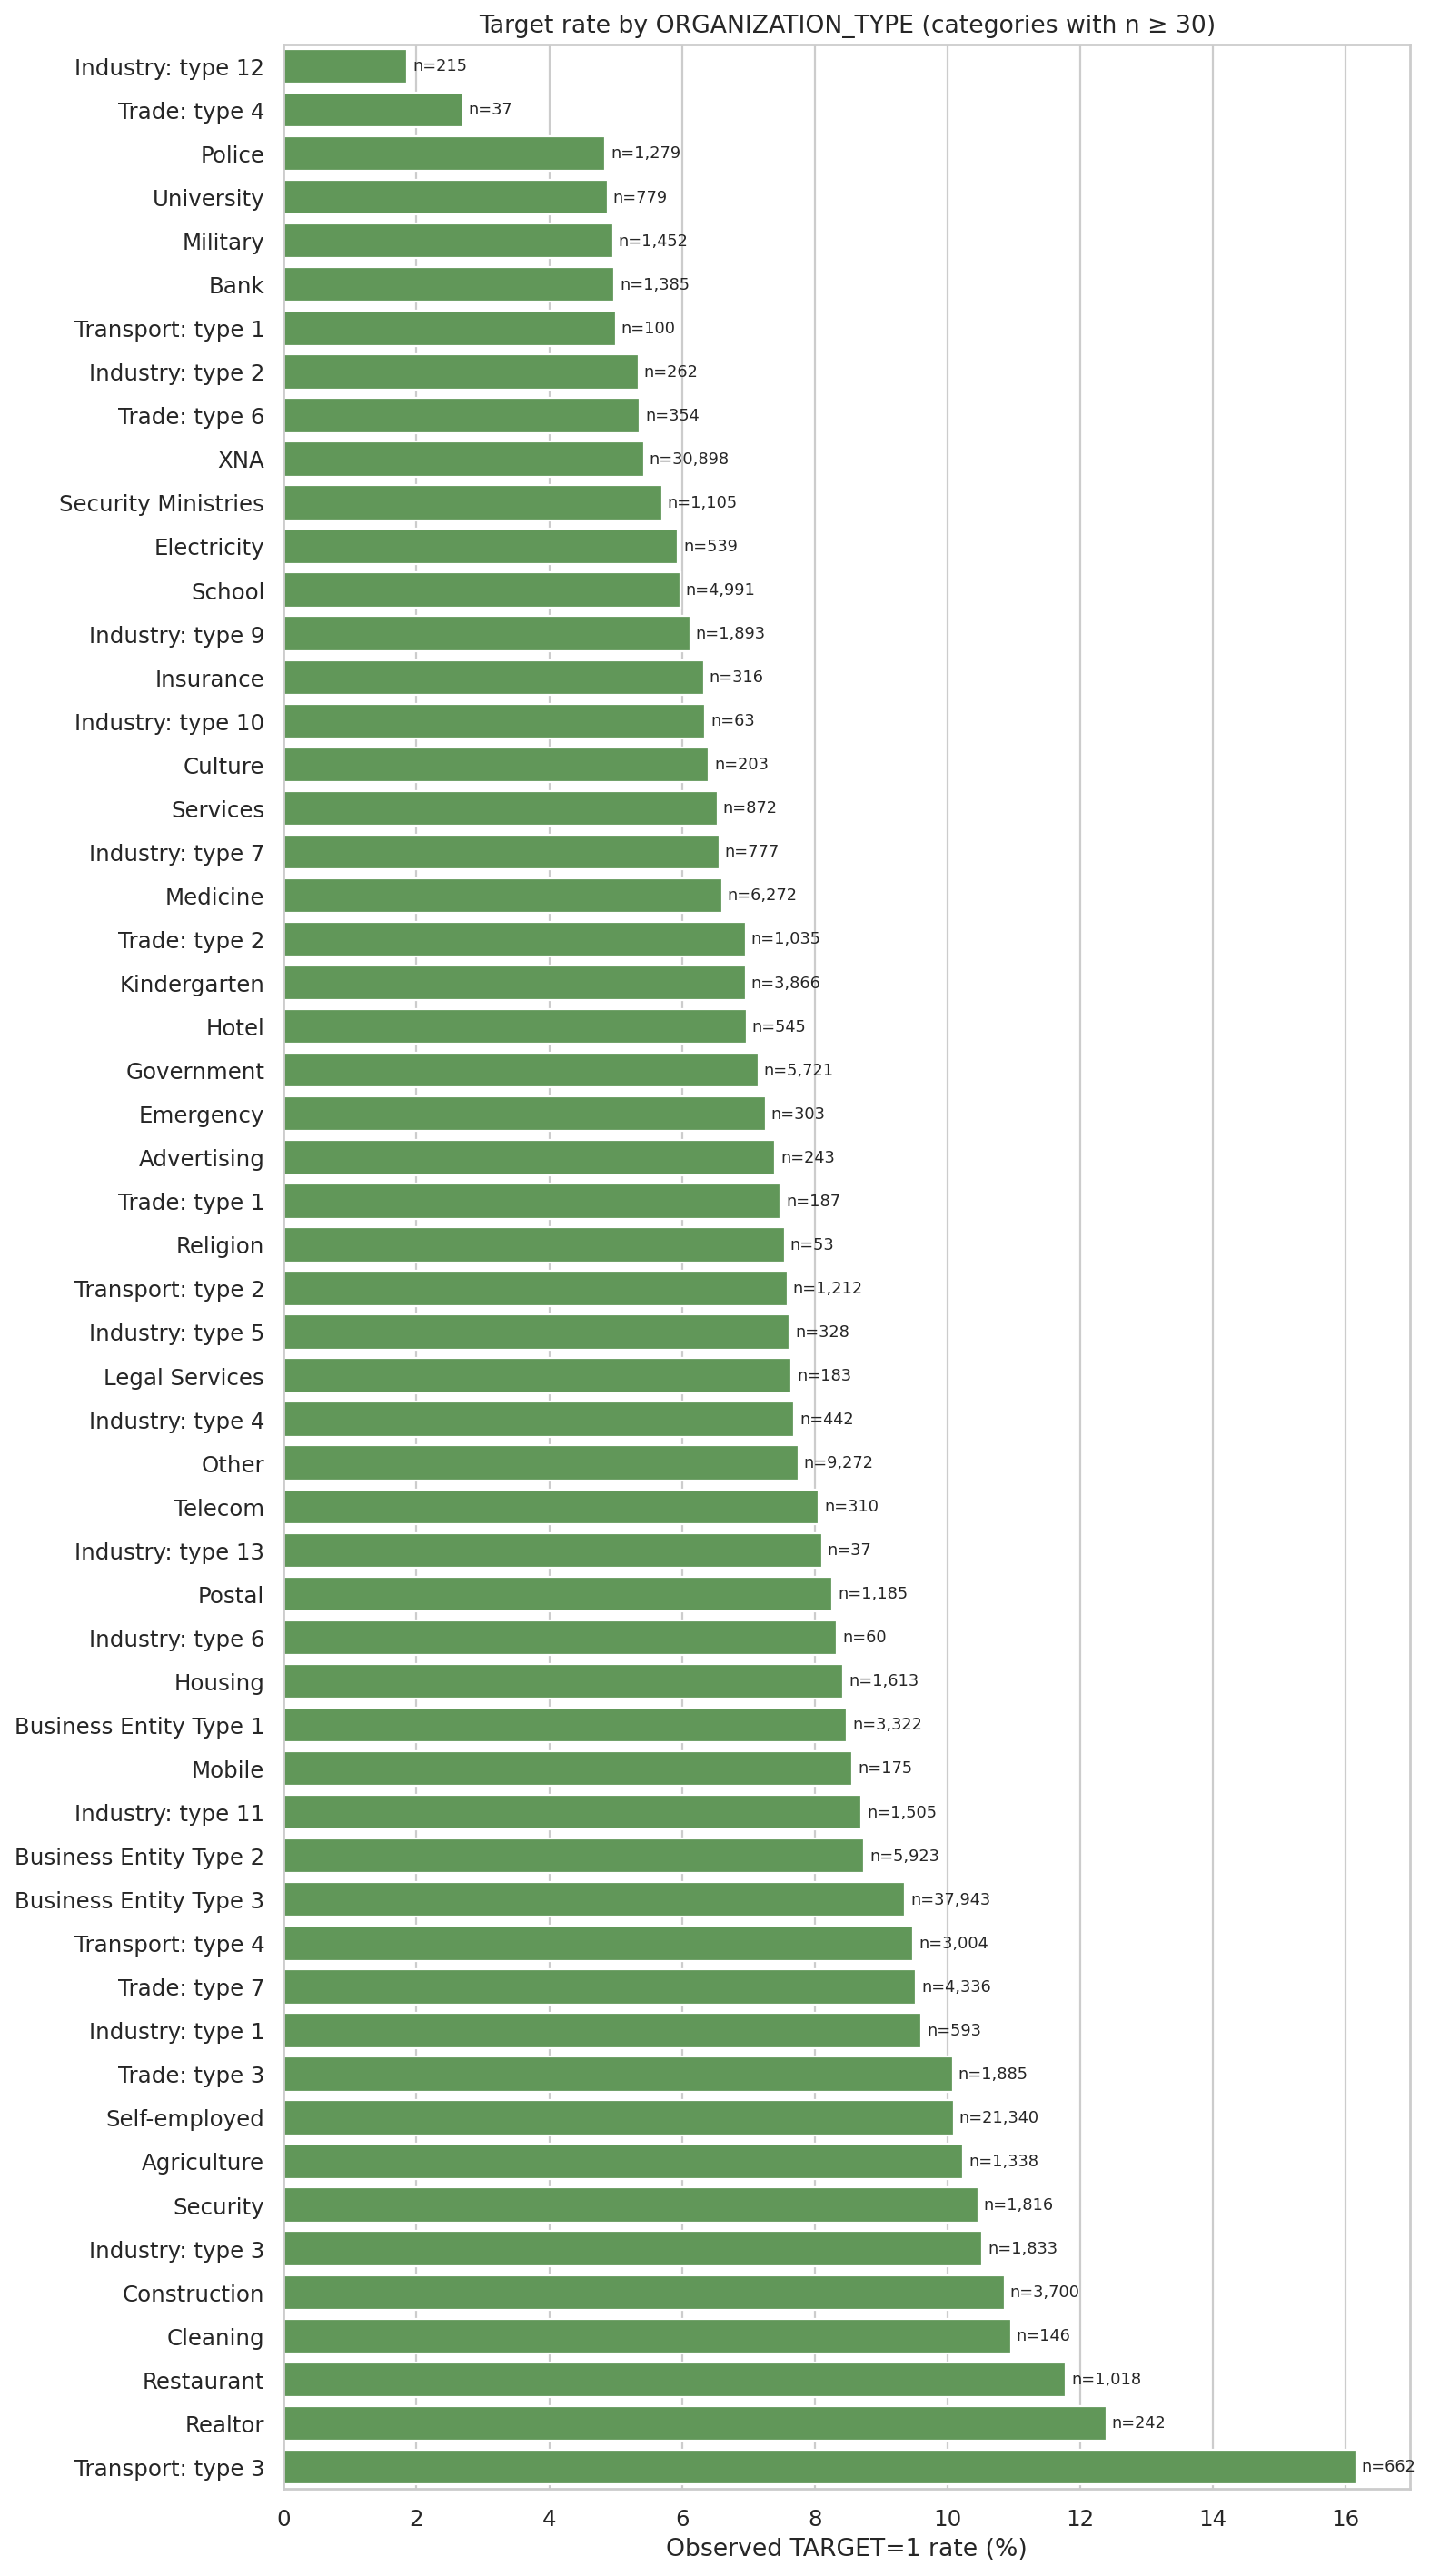

In [3]:
for f in ['05_numeric_correlations.png'] + sorted(p.name for p in (ROOT/'outputs/eda').glob('06_target_rate_*.png')):
    display(Image(filename=str(ROOT / 'outputs/eda' / f)))

## 4. Train/test distribution checks

The standardized mean difference (SMD) is a descriptive comparison of numerical means. Categorical total variation distance summarizes differences in category proportions. Small differences do not prove identical distributions, and the test target is unavailable.

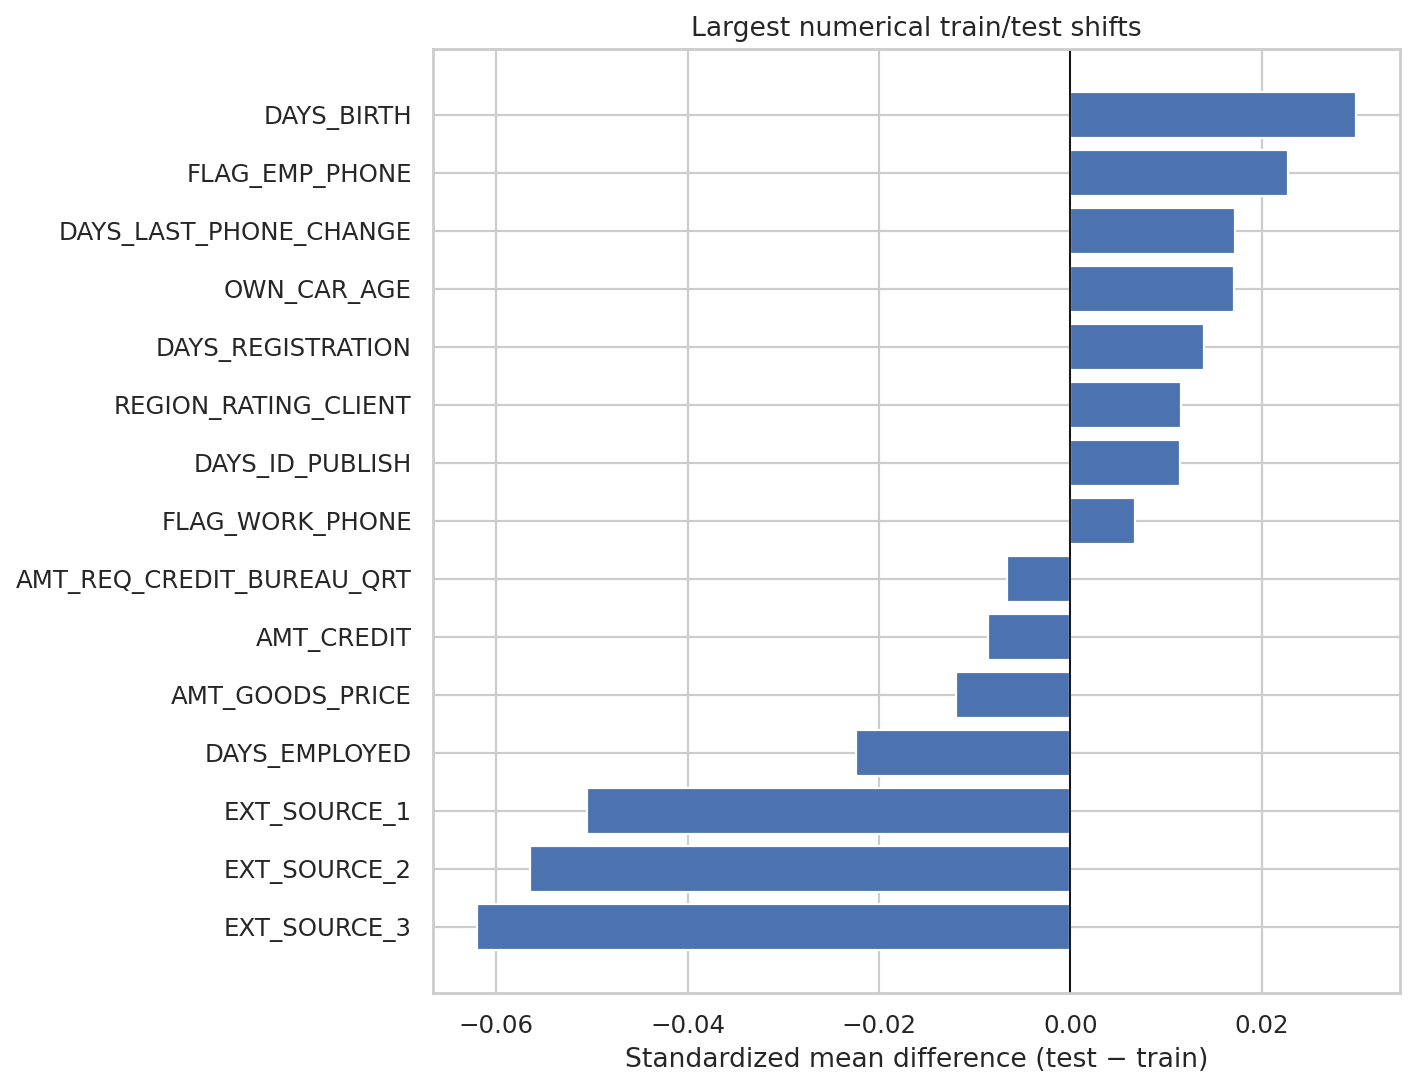

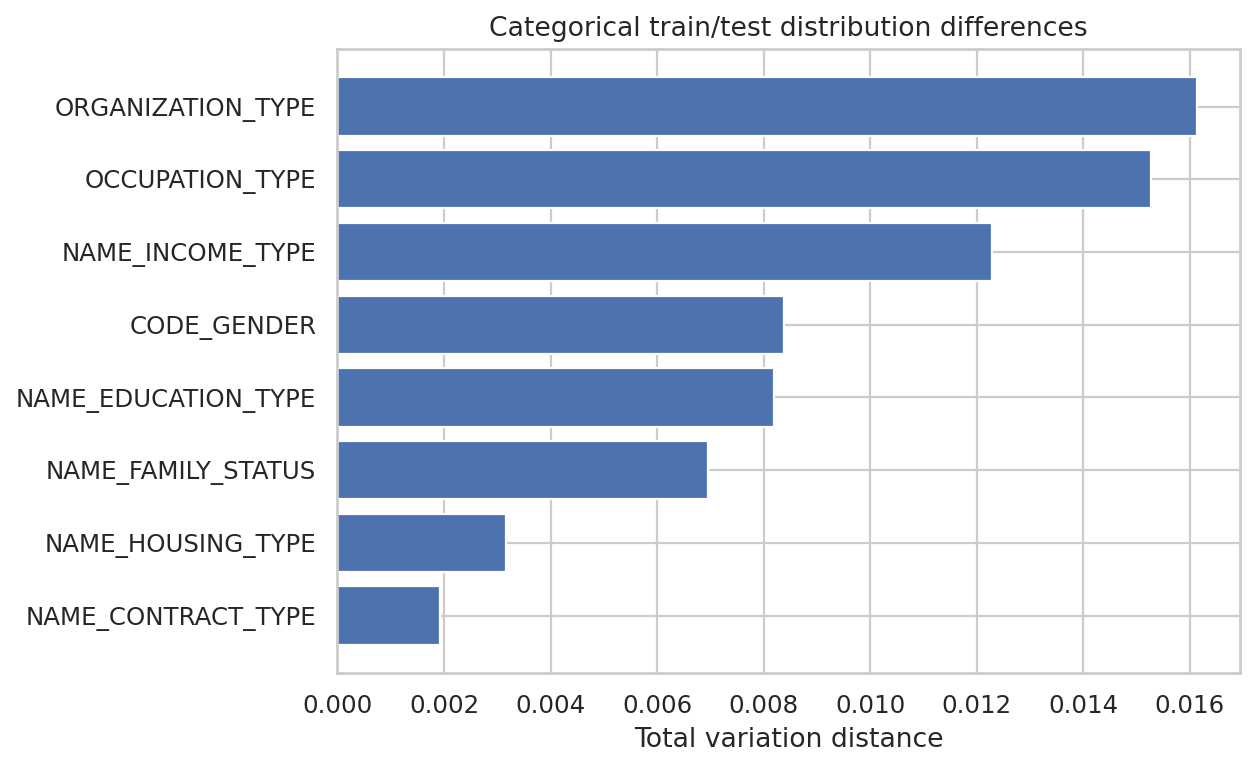

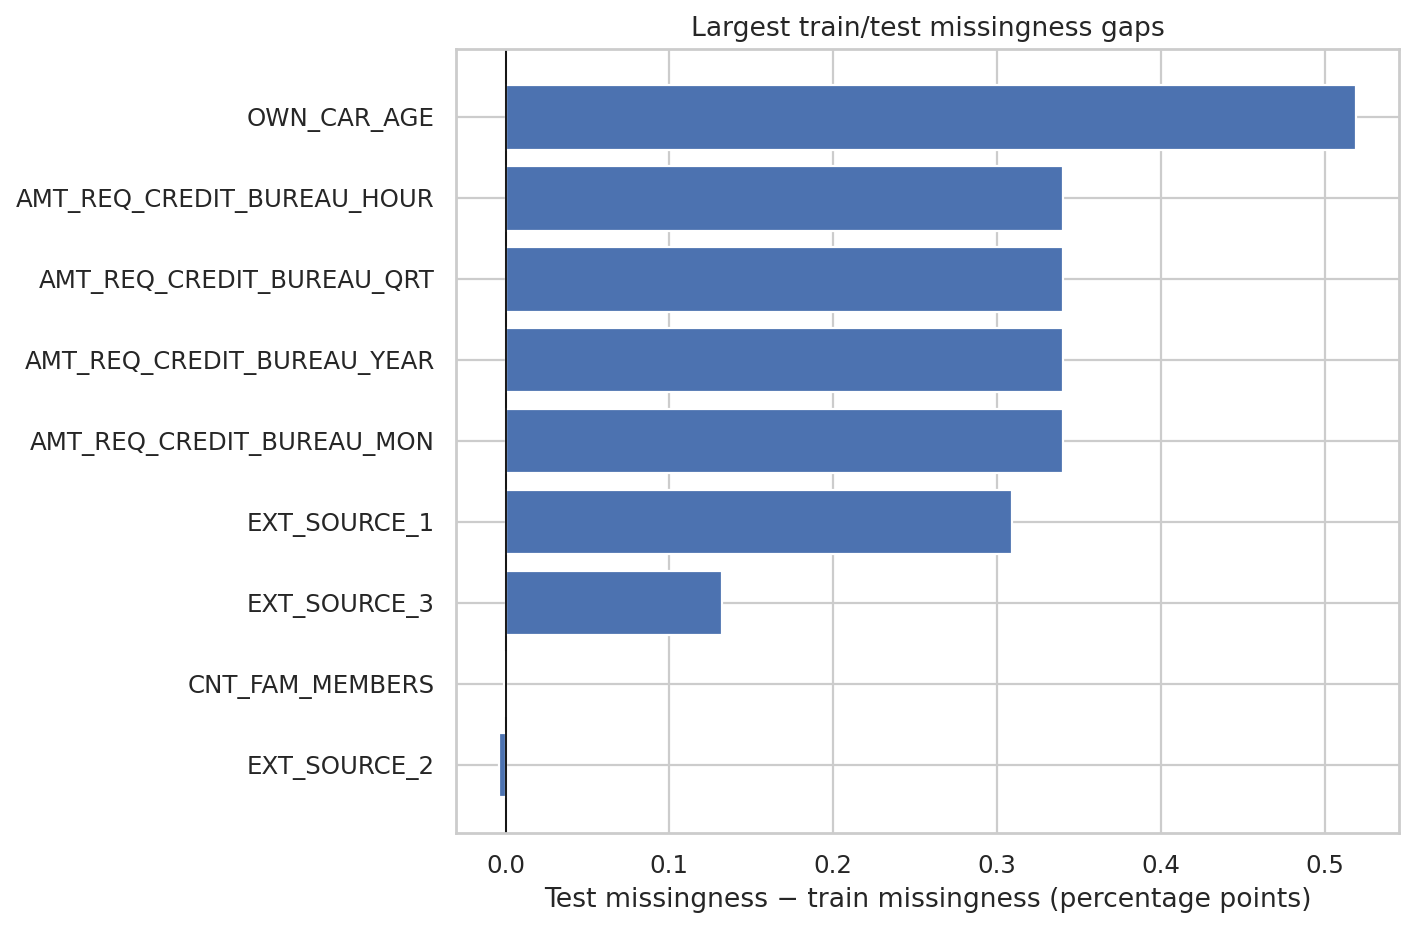

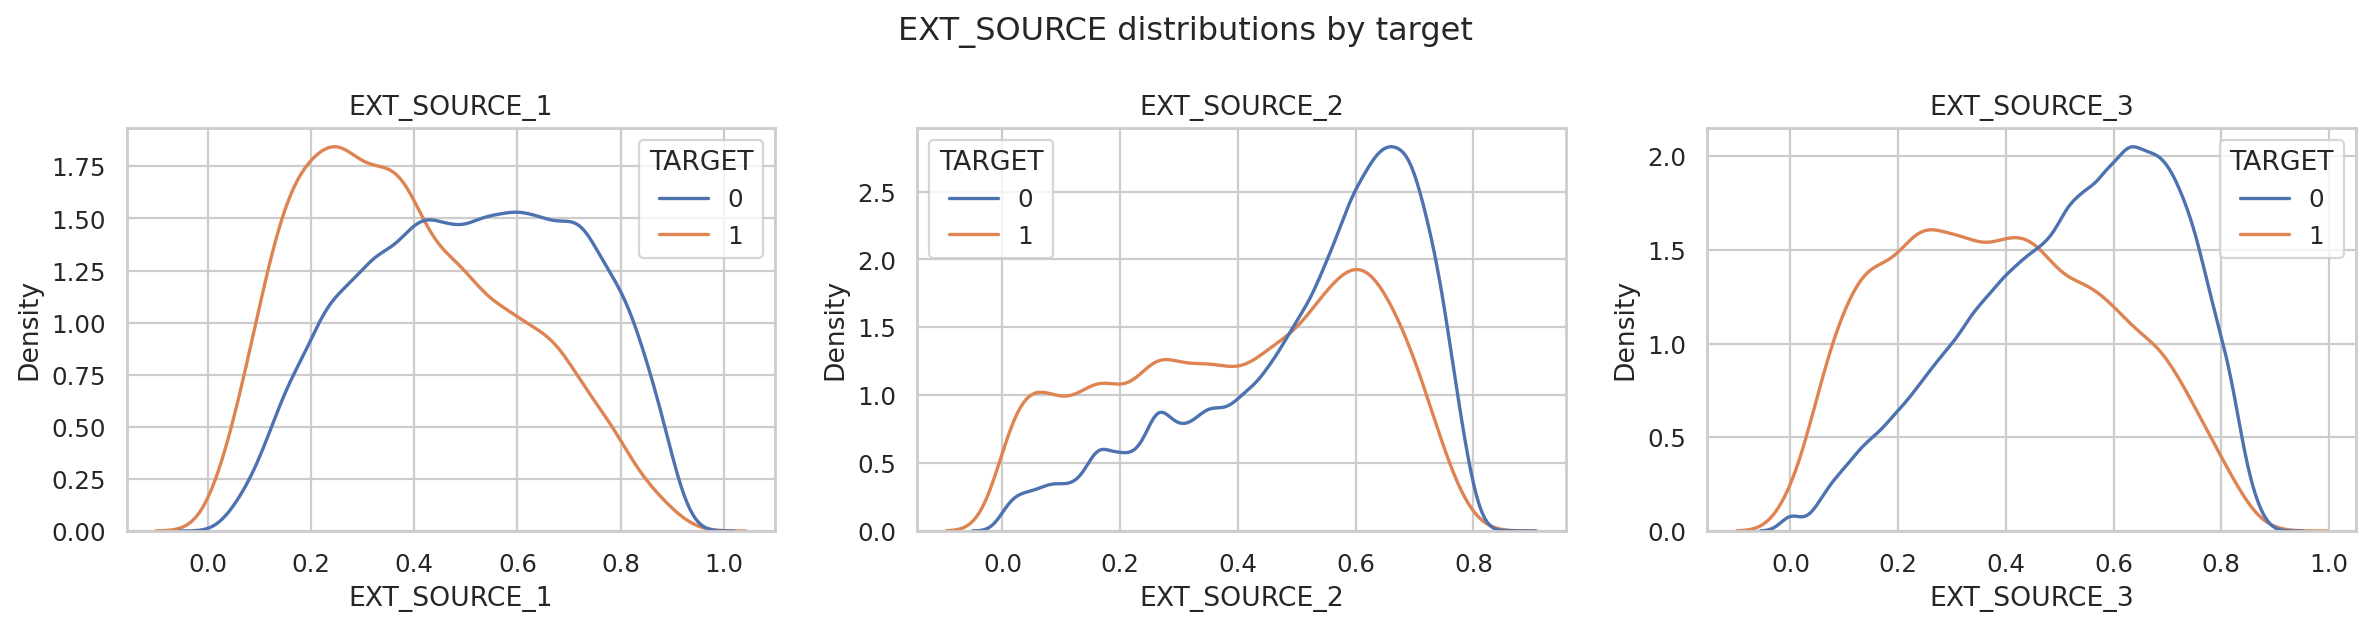

In [4]:
for f in ['07_numeric_train_test_drift.png','08_categorical_train_test_drift.png','09_missingness_shift.png','10_ext_source_by_target.png']:
    display(Image(filename=str(ROOT / 'outputs/eda' / f)))

## 5. Audit interpretation and limitations

- `DAYS_EMPLOYED` has a large positive sentinel-like value pattern; the feature pipeline flags positive values and does not interpret them as ordinary employment duration.
- `ORGANIZATION_TYPE='XNA'` is preserved as a category, not silently converted to missing.
- High missingness in `EXT_SOURCE_1` and `OWN_CAR_AGE` is visible in the missingness plot; imputation is handled inside the model pipeline.
- Correlations and category-level target rates are not causal evidence.
- Train/test plots are checks for obvious distribution differences, not proof that the test set is identical to training data.

Generated tables are in `outputs/eda/`. Re-run `python src/eda.py` to refresh all figures and tables.